<a href="https://colab.research.google.com/github/JeffinGeorgePalathingal/Bank_Customer_Churn/blob/main/notebooks/Project_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [88]:

import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import sklearn
import xgboost
import shap

print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgboost.__version__)
print("shap:", shap.__version__)


numpy: 2.1.3
pandas: 2.2.3
matplotlib: 3.10.0
seaborn: 0.13.2
scikit-learn: 1.6.1
xgboost: 3.4.1
shap: 0.52.0


In [15]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

from xgboost import XGBClassifier
import shap
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

#Importing the Data

In [16]:
df = pd.read_csv(
    "https://raw.githubusercontent.com/JeffinGeorgePalathingal/Bank_Customer_Churn/main/Data/Bank_Churn.csv"
)

#Data Inspection

In [17]:
df.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
# Checking for missing values
print("Missing values by column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Checking for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values by column:
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0


In [20]:
df.drop('CustomerId', axis=1, inplace=True)
df.drop('Surname', axis=1, inplace=True)

In [21]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


No missing values or duplicate records were identified.

#Exploratory Data Analysis

In [22]:
# Checking the distribution of the churn column
print("Customer churn distribution:")
print(df['Exited'].value_counts())

print("\nCustomer churn percentage:")
print(df['Exited'].value_counts(normalize=True) * 100)

Customer churn distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64

Customer churn percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


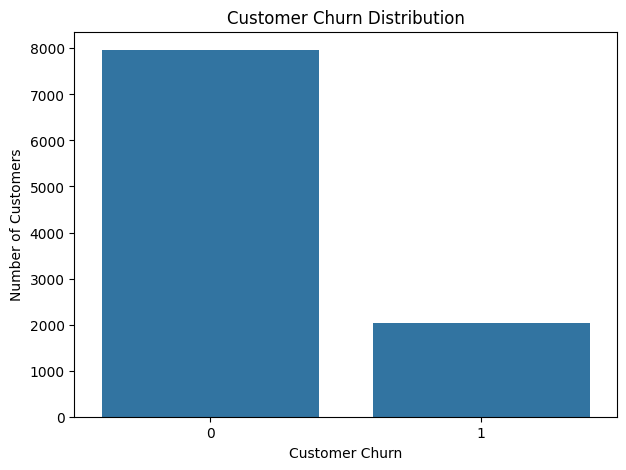

In [23]:
# Customer churn distribution

plt.figure(figsize=(7, 5))

sns.countplot(x='Exited', data=df)

plt.title('Customer Churn Distribution')
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')

plt.show()

The target variable, Exited, is imbalanced, with non-churned customers representing the majority of observations. This class distribution will be considered when splitting the data and evaluating the classification models.

Activity Status: An active customer is one who has made at least one financial transaction with the bank within the previous 12 months.

In [24]:
pd.crosstab(
    df['IsActiveMember'],
    df['Exited'],
    normalize='index'
) * 100

Exited,0,1
IsActiveMember,,
0,73.149103,26.850897
1,85.730926,14.269074


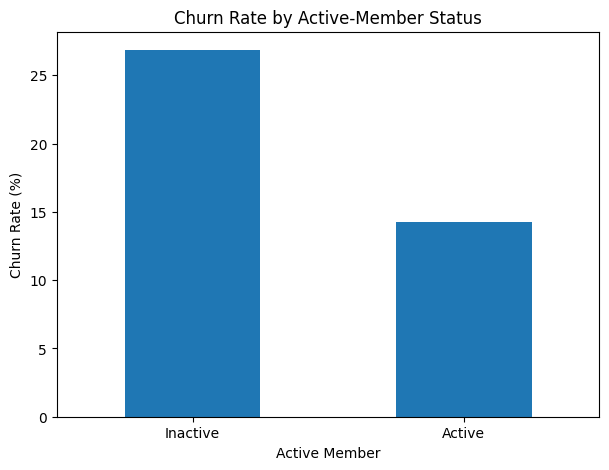

In [25]:
# Churn rate by active-member status

active_churn = pd.crosstab(
    df['IsActiveMember'],
    df['Exited'],
    normalize='index'
) * 100

active_churn[1].plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Churn Rate by Active-Member Status')
plt.xlabel('Active Member')
plt.ylabel('Churn Rate (%)')
plt.xticks([0, 1], ['Inactive', 'Active'], rotation=0)

plt.show()

Inactive customers show a higher churn rate of 26.85%, compared with 14.27% among active customers, suggesting that customer activity is associated with customer retention.

---



Number of Products


In [26]:
# Mode and frequency of number of products

print(df['NumOfProducts'].value_counts().sort_index())

NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64


In [27]:
# Churn rate by number of products

product_churn = pd.crosstab(
    df['NumOfProducts'],
    df['Exited'],
    normalize='index'
) * 100

product_churn

Exited,0,1
NumOfProducts,,
1,72.285602,27.714398
2,92.418301,7.581699
3,17.293233,82.706767
4,0.000000,100.000000


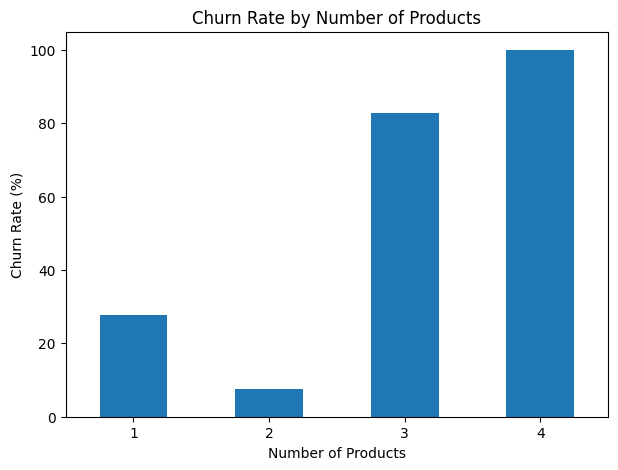

In [28]:
# Churn rate by number of products

product_churn[1].plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Churn Rate by Number of Products')
plt.xlabel('Number of Products')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

In [29]:
product_churn = pd.crosstab(
    df['NumOfProducts'],
    df['Exited'],
)

product_churn

Exited,0,1
NumOfProducts,,
1,3675,1409
2,4242,348
3,46,220
4,0,60


Churn rate by Geography

In [30]:
geography_churn = pd.crosstab(
    df['Geography'],
    df['Exited'],
    normalize='index'
) * 100

print(geography_churn)

Exited             0          1
Geography                      
France     83.845233  16.154767
Germany    67.556796  32.443204
Spain      83.326605  16.673395


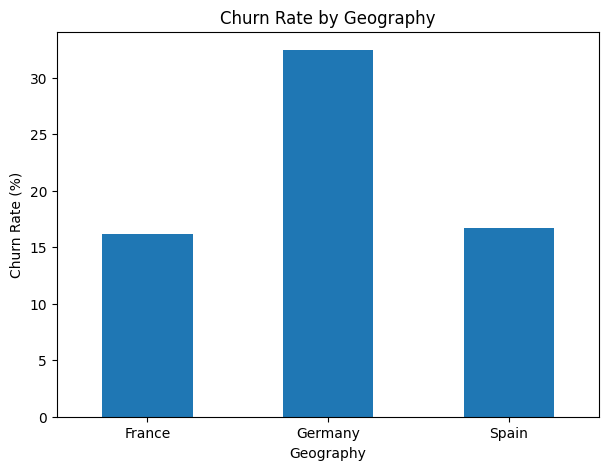

In [31]:
geography_churn[1].plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Churn Rate by Geography')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

Churn rate by age group

In [32]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17, 29, 39, 49, 59, 69, 100],
    labels=['18-29', '30-39', '40-49', '50-59', '60-69', '70+']
)

age_churn = pd.crosstab(
    df['AgeGroup'],
    df['Exited'],
    normalize='index'
) * 100

age_churn

Exited,0,1
AgeGroup,,
18-29,92.443632,7.556368
30-39,89.116429,10.883571
40-49,69.213140,30.786860
50-59,43.958573,56.041427
60-69,64.800000,35.200000
70+,90.066225,9.933775


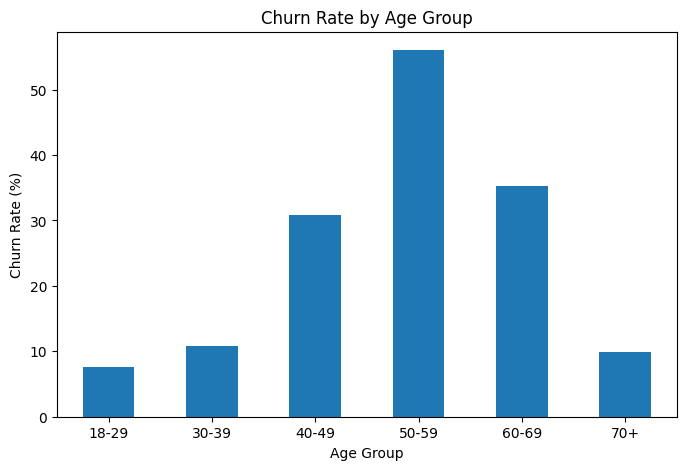

In [33]:
age_churn[1].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

In [34]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17, 29, 39, 49, 59, 69, 100],
    labels=['18-29', '30-39', '40-49', '50-59', '60-69', '70+']
)

# Actual values instead of percentages

age_churn = pd.crosstab(
    df['AgeGroup'],
    df['Exited']
)

age_churn

Exited,0,1
AgeGroup,,
18-29,1517,124
30-39,3873,473
40-49,1812,806
50-59,382,487
60-69,243,132
70+,136,15


Credit Score range

In [35]:
df['CreditScoreRange'] = pd.cut(
    df['CreditScore'],
    bins=[300, 579, 669, 739, 799, 850],
    labels=['Poor', 'Fair', 'Good', 'Very Good', 'Excellent']
)


credit_churn = pd.crosstab(
    df['CreditScoreRange'],
    df['Exited'],
    normalize='index'
) * 100

credit_churn

Exited,0,1
CreditScoreRange,,
Poor,77.984759,22.015241
Fair,79.435605,20.564395
Good,81.383855,18.616145
Very Good,79.411765,20.588235
Excellent,80.458015,19.541985


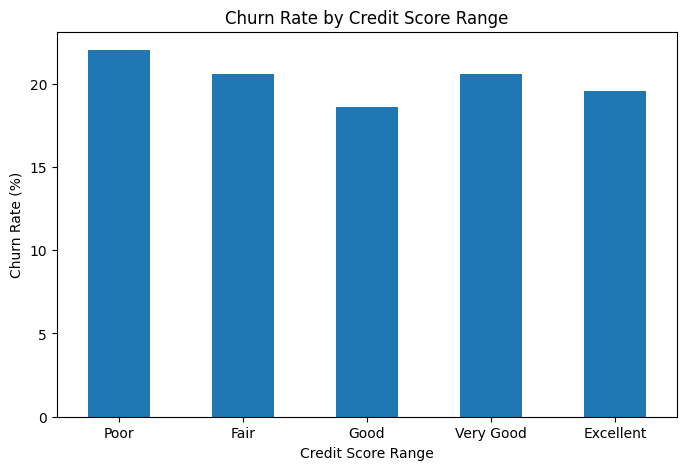

In [36]:
# Churn rate by credit-score range

credit_churn[1].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Churn Rate by Credit Score Range')
plt.xlabel('Credit Score Range')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

Balance Distribution by Churn Status

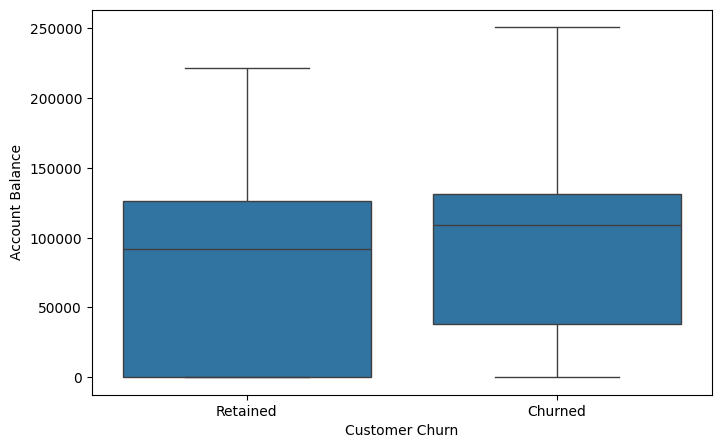

In [37]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x='Exited',
    y='Balance',
    data=df
)

#plt.title('Balance Distribution by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Account Balance')
plt.xticks([0, 1], ['Retained', 'Churned'])

plt.show()

In [38]:
# Balance statistics by churn status

df.groupby('Exited')['Balance'].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,7963.0,72745.296779,62848.040701,0.0,0.00,92072.68,126410.28,221532.80
1,2037.0,91108.539337,58360.794816,0.0,38340.02,109349.29,131433.33,250898.09


In [39]:
# Non-churned customers who are inactive and have zero balance

df[
    (df['Exited'] == 0) &
    (df['IsActiveMember'] == 0) &
    (df['Balance'] == 0)
].shape[0]

1424

In [40]:
# Profile of inactive, zero-balance, non-churned customers

inactive_zero_balance = df[
    (df['Exited'] == 0) &
    (df['IsActiveMember'] == 0) &
    (df['Balance'] == 0)
]

print("Number of customers:", len(inactive_zero_balance))

print("\nCredit card ownership:")
print(inactive_zero_balance['HasCrCard'].value_counts())

print("\nNumber of products:")
print(inactive_zero_balance['NumOfProducts'].value_counts().sort_index())

Number of customers: 1424

Credit card ownership:
HasCrCard
1    1015
0     409
Name: count, dtype: int64

Number of products:
NumOfProducts
1     250
2    1160
3      14
Name: count, dtype: int64


In [41]:
# Remove low-balance and inactive customers for balance analysis

balance_df = df[
    ~(
        (df['IsActiveMember'] == 0) &
        (df['Balance'] < 1000)
    )
].copy()

In [42]:
print("Original observations:", len(df))
print("Observations after cleaning:", len(balance_df))
print("Observations removed:", len(df) - len(balance_df))

Original observations: 10000
Observations after cleaning: 8256
Observations removed: 1744


In [43]:
# Churn status of removed customers

removed_customers = df[
    (df['IsActiveMember'] == 0) &
    (df['Balance'] < 1000)
]

print(removed_customers['Exited'].value_counts())

Exited
0    1424
1     320
Name: count, dtype: int64


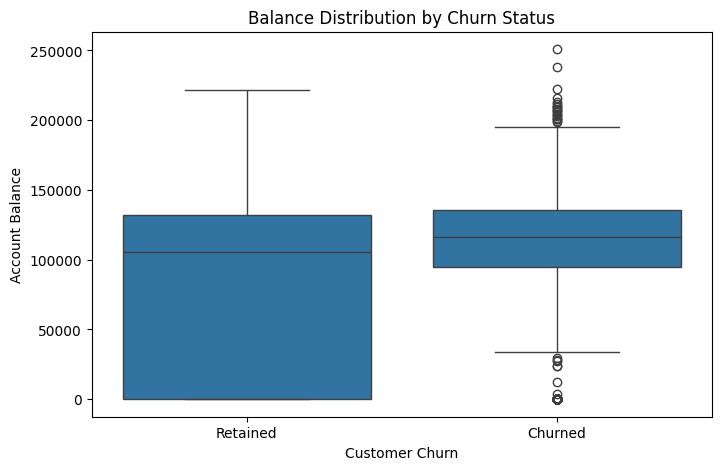

In [44]:
# Balance distribution by churn status after cleaning

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='Exited',
    y='Balance',
    data=balance_df
)

plt.title('Balance Distribution by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Account Balance')
plt.xticks([0, 1], ['Retained', 'Churned'])

plt.show()

In [45]:
# Balance statistics by churn status after cleaning

balance_df.groupby('Exited')['Balance'].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,6539.0,88587.061974,58365.94413,0.0,0.00,105563.00,132122.065,221532.80
1,1717.0,108088.581613,46954.36469,0.0,94598.48,116546.59,135555.660,250898.09


Churned customers have a slightly higher median balance than retained customers. The overall difference between the distributions is small. The higher-balance outliers seem to be churning.

Tenure Distribution by Churn Status

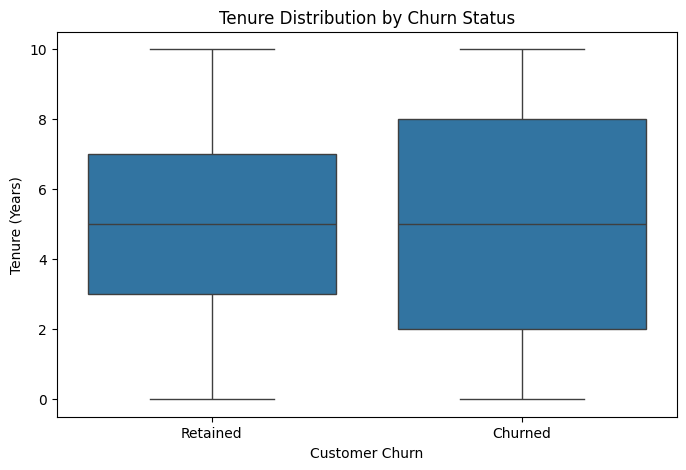

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x='Exited',
    y='Tenure',
    data=df
)

plt.title('Tenure Distribution by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Tenure (Years)')
plt.xticks([0, 1], ['Retained', 'Churned'])

plt.show()

In [47]:
# Tenure statistics by churn status

df.groupby('Exited')['Tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0,7963.0,5.033279,2.880658,0.0,3.0,5.0,7.0,10.0
1,2037.0,4.932744,2.936106,0.0,2.0,5.0,8.0,10.0


Tenure shows little difference between churned and retained customers, with both groups having a median tenure of five years.

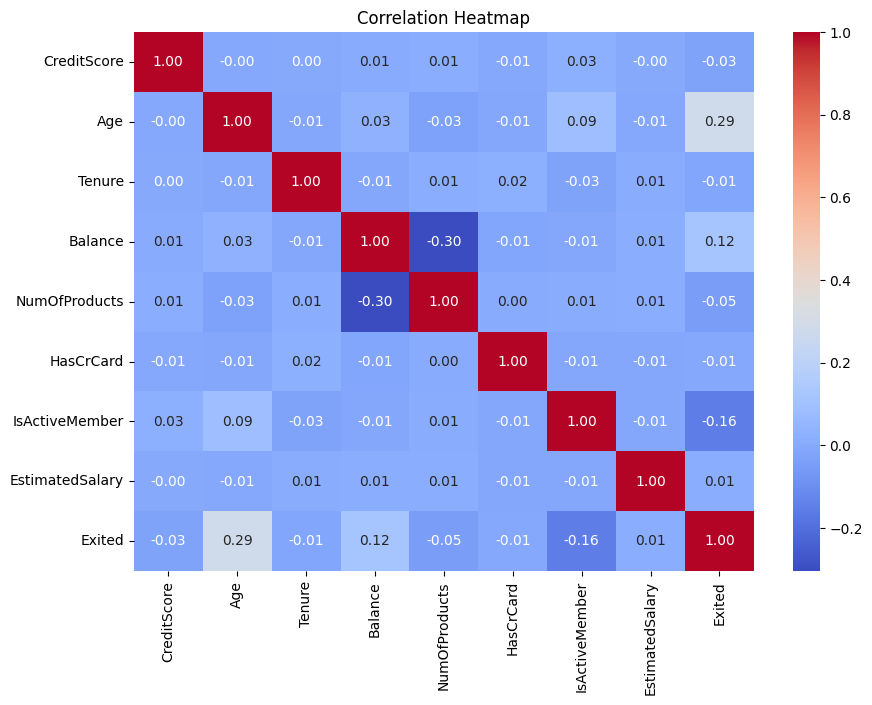

In [48]:
# Correlation heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

The correlation analysis shows that age has the strongest linear relationship with churn, while most other variables show relatively weak correlations.

Age, customer activity, number of products and geography show the clearest differences in observed churn, while tenure, credit score and account balance show comparatively weaker relationships.

#Encoding Categorical Variables

Geography and Gender are encoded into numerical variables so they can be used by the machine learning models.

In [49]:
# Remove EDA-only columns

df_model = df.drop(
    columns=['AgeGroup', 'CreditScoreRange']
).copy()

# Encode categorical variables

df_model = pd.get_dummies(
    df_model,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)

df_model.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


#Feature Scaling

Numerical features are standardised so that variables with different scales have a comparable influence when training the Logistic Regression model. Fitting is done only on the train data and not the test.

In [50]:
# Separate features and target

X = df_model.drop('Exited', axis=1)
y = df_model['Exited']

# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [51]:
# Check the size of the training and testing sets

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training set: (8000, 11)
Testing set: (2000, 11)

Training target distribution:
Exited
0    79.625
1    20.375
Name: proportion, dtype: float64

Testing target distribution:
Exited
0    79.65
1    20.35
Name: proportion, dtype: float64


In [52]:
# Feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert scaled data back to DataFrames

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

X_train_scaled.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
2151,1.058568,1.715086,0.684723,-1.226059,-0.910256,0.641042,-1.030206,1.042084,-0.578313,-0.577735,0.907507
8392,0.913626,-0.659935,-0.696202,0.413288,-0.910256,0.641042,-1.030206,-0.623556,1.729169,-0.577735,0.907507
5006,1.079274,-0.184931,-1.731895,0.601687,0.808830,0.641042,0.970680,0.308128,1.729169,-0.577735,-1.101919
4117,-0.929207,-0.184931,-0.005739,-1.226059,0.808830,0.641042,-1.030206,-0.290199,-0.578313,-0.577735,0.907507
7182,0.427035,0.955079,0.339492,0.548318,0.808830,-1.559960,0.970680,0.135042,1.729169,-0.577735,0.907507


#Logistic Regression

In [53]:
# Logistic Regression

logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

In [54]:
# Predictions

y_pred_logistic = logistic_model.predict(X_test_scaled)
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]
y_prob_logistic[:10]

array([0.11817946, 0.2794762 , 0.11237068, 0.14670642, 0.09520189,
       0.13702923, 0.08663198, 0.35626774, 0.35570702, 0.21459754])

## Baseline

The baseline assumes every customer is being retained. This gives as a better perspective on the accuracy of the different models that we are using.

In [55]:
# Baseline prediction using the majority class

baseline_pred = np.zeros(len(y_test), dtype=int)

print("Baseline churn probability:", y.mean())
print("Baseline predicted churn rate:", baseline_pred.mean())

Baseline churn probability: 0.2037
Baseline predicted churn rate: 0.0


In [56]:
# Baseline performance

print("Accuracy:", accuracy_score(y_test, baseline_pred))
print("Precision:", precision_score(y_test, baseline_pred, zero_division=0))
print("Recall:", recall_score(y_test, baseline_pred))
print("F1 Score:", f1_score(y_test, baseline_pred))

Accuracy: 0.7965
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [57]:
# Logistic Regression performance

print("Accuracy:", accuracy_score(y_test, y_pred_logistic)*100)
print("Precision:", precision_score(y_test, y_pred_logistic)*100)
print("Recall:", recall_score(y_test, y_pred_logistic)*100)
print("F1 Score:", f1_score(y_test, y_pred_logistic)*100)
print("ROC-AUC:", roc_auc_score(y_test, y_prob_logistic))

Accuracy: 80.80000000000001
Precision: 58.91472868217055
Recall: 18.67321867321867
F1 Score: 28.35820895522388
ROC-AUC: 0.7747778595236223


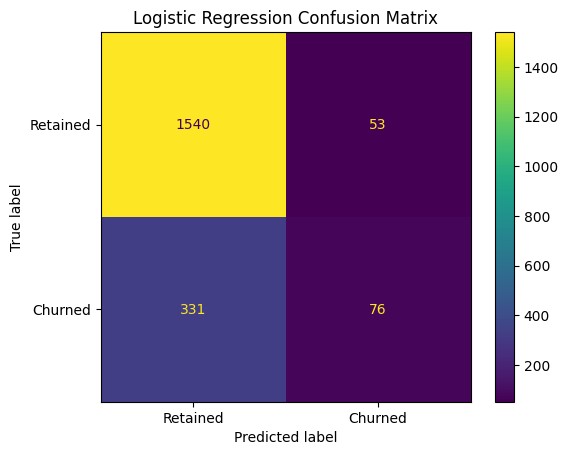

In [58]:
# Logistic Regression confusion matrix

cm_logistic = confusion_matrix(y_test, y_pred_logistic)

# Plot confusion matrix

ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=['Retained', 'Churned']
).plot()

plt.title('Logistic Regression Confusion Matrix')
plt.show()

#Random Forest

In [59]:
rf_model = RandomForestClassifier(
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

RandomForestClassifier(random_state=42)

In [60]:
# Random Forest predictions

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [61]:
# Random Forest performance

print("Accuracy:", accuracy_score(y_test, y_pred_rf) * 100)
print("Precision:", precision_score(y_test, y_pred_rf) * 100)
print("Recall:", recall_score(y_test, y_pred_rf) * 100)
print("F1 Score:", f1_score(y_test, y_pred_rf) * 100)
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Accuracy: 86.45
Precision: 78.33333333333333
Recall: 46.19164619164619
F1 Score: 58.11437403400309
ROC-AUC: 0.852629208561412


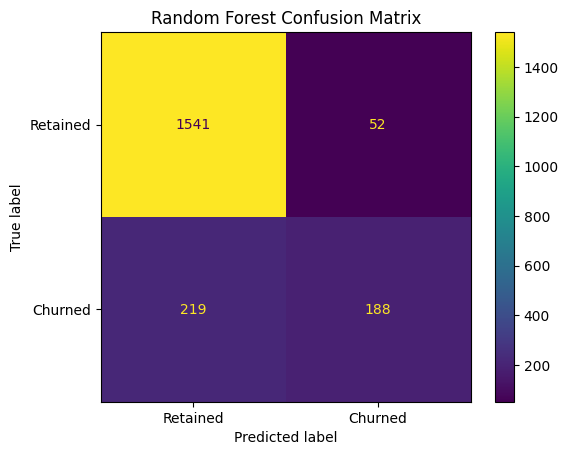

In [62]:
# Random Forest confusion matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Retained', 'Churned']
).plot()

plt.title('Random Forest Confusion Matrix')
plt.show()

Random Forest performs better than the baseline and Logistic Regression, with improved precision and recall. However, the model still misses more than half of the customers who actually churned, limiting its usefulness for proactive retention.

#XGBoost

In [63]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(
    X_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [64]:
# XGBoost predictions

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# XGBoost performance

print("Accuracy:", accuracy_score(y_test, y_pred_xgb) * 100)
print("Precision:", precision_score(y_test, y_pred_xgb) * 100)
print("Recall:", recall_score(y_test, y_pred_xgb) * 100)
print("F1 Score:", f1_score(y_test, y_pred_xgb) * 100)
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

Accuracy: 85.35000000000001
Precision: 69.25675675675676
Recall: 50.368550368550366
F1 Score: 58.32147937411095
ROC-AUC: 0.8332616129226299


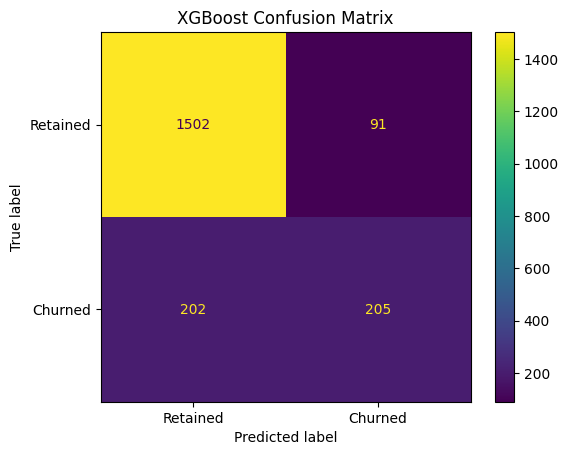

In [65]:
# XGBoost confusion matrix

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=['Retained', 'Churned']
).plot()

plt.title('XGBoost Confusion Matrix')
plt.show()

XGBoost identifies more churned customers than Random Forest, achieving higher recall but lower precision. Overall F1 performance is almost identical, indicating that neither model clearly outperforms the other at the default classification threshold.

## Random Forest Hyper Tuning

Hyperparameters are tuned to improve the model's ability to identify customers who churn, with recall used as the primary evaluation metric.

In [66]:
# Random Forest parameter grid
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

In [67]:
rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_param_grid,
    n_iter=40,
    scoring='recall',
    cv=5,
    random_state=42,
    n_jobs=-1
)

rf_random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
                   n_iter=40, n_jobs=-1,
                   param_distributions={'class_weight': [None, 'balanced'],
                                        'max_depth': [None, 10, 20],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 200, 300]},
                   random_state=42, scoring='recall')

In [68]:
# Best Random Forest parameters

print("Best parameters:")
print(rf_random_search.best_params_)

print("\nBest cross-validation recall:")
print(rf_random_search.best_score_)

Best parameters:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 10, 'class_weight': 'balanced'}

Best cross-validation recall:
0.6662576687116564


In [69]:
# Tuned Random Forest predictions

best_rf = rf_random_search.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)
y_prob_rf_tuned = best_rf.predict_proba(X_test)[:, 1]

In [70]:
# Tuned Random Forest performance

print("Accuracy:", accuracy_score(y_test, y_pred_rf_tuned) * 100)
print("Precision:", precision_score(y_test, y_pred_rf_tuned) * 100)
print("Recall:", recall_score(y_test, y_pred_rf_tuned) * 100)
print("F1 Score:", f1_score(y_test, y_pred_rf_tuned) * 100)
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf_tuned))

Accuracy: 83.45
Precision: 57.98319327731093
Recall: 67.81326781326781
F1 Score: 62.51415628539071
ROC-AUC: 0.8652535432196448


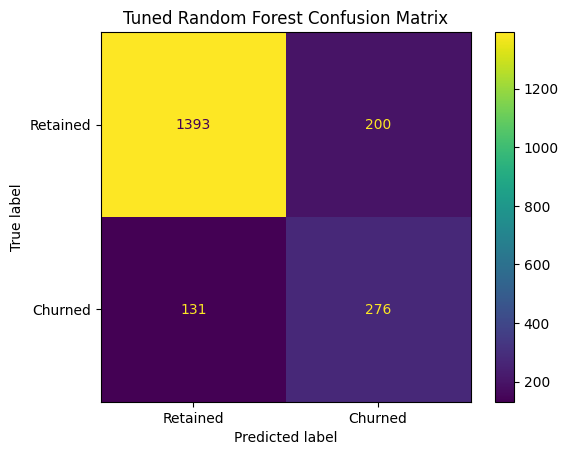

In [71]:
# Tuned Random Forest confusion matrix

cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_tuned,
    display_labels=['Retained', 'Churned']
).plot()

plt.title('Tuned Random Forest Confusion Matrix')
plt.show()

The tuned Random Forest improves recall, identifying 67.81% of churned customers, but this comes at the cost of lower precision and accuracy due to a higher number of false positives.

## XGBoost Hyperparameter Tuning

In [72]:
# XGBoost parameter grid

xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.3],
    'scale_pos_weight': [1, 2, 3]
}

In [73]:
# XGBoost randomized search

xgb_random_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ),
    param_distributions=xgb_param_grid,
    n_iter=40,
    scoring='recall',
    cv=5,
    random_state=42,
    n_jobs=-1
)

xgb_random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_const...
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=40, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.8, 1.0],
                                        'gamma': [0, 0.1, 0.3],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [3, 5, 7],
                                        'min_child_weight': [1, 3, 5],
                                        'n_estimators': [100, 200, 300],
                                        'scale_pos_weight': [1, 2, 3],
                                        'subsample': [0.8, 1.0]},
                   random_state=42, scoring='recall')

In [74]:
# Best XGBoost parameters

print("Best parameters:")
print(xgb_random_search.best_params_)

print("\nBest cross-validation recall:")
print(xgb_random_search.best_score_)

Best parameters:
{'subsample': 0.8, 'scale_pos_weight': 3, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.8}

Best cross-validation recall:
0.6957055214723926


In [75]:
# Tuned XGBoost predictions

best_xgb = xgb_random_search.best_estimator_

y_pred_xgb_tuned = best_xgb.predict(X_test)
y_prob_xgb_tuned = best_xgb.predict_proba(X_test)[:, 1]

# Tuned XGBoost performance

print("Accuracy:", accuracy_score(y_test, y_pred_xgb_tuned) * 100)
print("Precision:", precision_score(y_test, y_pred_xgb_tuned) * 100)
print("Recall:", recall_score(y_test, y_pred_xgb_tuned) * 100)
print("F1 Score:", f1_score(y_test, y_pred_xgb_tuned) * 100)
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb_tuned))

Accuracy: 83.15
Precision: 56.889763779527556
Recall: 71.007371007371
F1 Score: 63.169398907103826
ROC-AUC: 0.8706765316934808


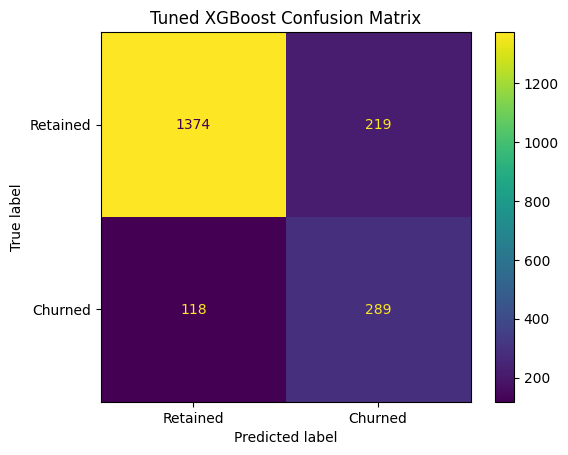

In [76]:
# Tuned XGBoost confusion matrix

cm_xgb_tuned = confusion_matrix(y_test, y_pred_xgb_tuned)

ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb_tuned,
    display_labels=['Retained', 'Churned']
).plot()

plt.title('Tuned XGBoost Confusion Matrix')
plt.show()

## Model Performance Comparison

The baseline, untuned models and tuned models are compared using accuracy, precision, recall, F1-score and ROC-AUC to assess their predictive performance on the test set.

In [77]:
# Model performance comparison

model_results = {
    'Baseline': (baseline_pred, None),
    'Logistic Regression': (y_pred_logistic, y_prob_logistic),
    'Random Forest': (y_pred_rf, y_prob_rf),
    'Tuned Random Forest': (y_pred_rf_tuned, y_prob_rf_tuned),
    'XGBoost': (y_pred_xgb, y_prob_xgb),
    'Tuned XGBoost': (y_pred_xgb_tuned, y_prob_xgb_tuned)
}

results = []

for model_name, (y_pred, y_prob) in model_results.items():
    results.append({
        'Model': model_name,
        'Accuracy (%)': accuracy_score(y_test, y_pred) * 100,
        'Precision (%)': precision_score(
            y_test, y_pred, zero_division=0
        ) * 100,
        'Recall (%)': recall_score(
            y_test, y_pred, zero_division=0
        ) * 100,
        'F1 Score (%)': f1_score(
            y_test, y_pred, zero_division=0
        ) * 100,
        'ROC-AUC': (
            roc_auc_score(y_test, y_prob)
            if y_prob is not None else np.nan
        )
    })

model_comparison = pd.DataFrame(results)

model_comparison.round(2)

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC
0,Baseline,79.65,0.00,0.00,0.00,NaN
1,Logistic Regression,80.80,58.91,18.67,28.36,0.77
2,Random Forest,86.45,78.33,46.19,58.11,0.85
3,Tuned Random Forest,83.45,57.98,67.81,62.51,0.87
4,XGBoost,85.35,69.26,50.37,58.32,0.83
5,Tuned XGBoost,83.15,56.89,71.01,63.17,0.87


The untuned Random Forest achieves the highest precision and accuracy, while tuned XGBoost achieves the highest recall, F1-score and ROC-AUC. The final model selection will depend on the bank's retention objectives and intervention costs.

## Feature Importance

Feature importance is examined to identify which customer characteristics contribute most to the predictions made by the tuned Random Forest and XGBoost models.

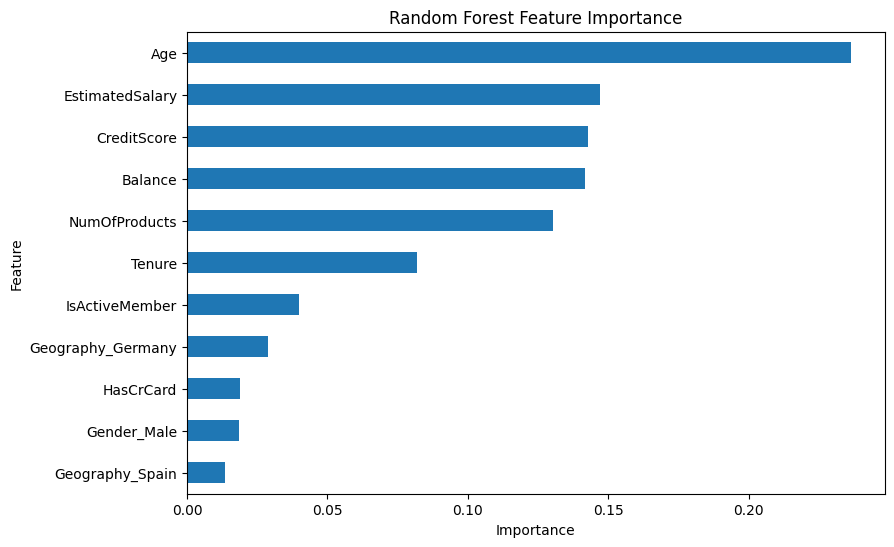

In [78]:
# Random Forest feature importance

rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))

rf_importance.sort_values().plot(kind='barh')

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

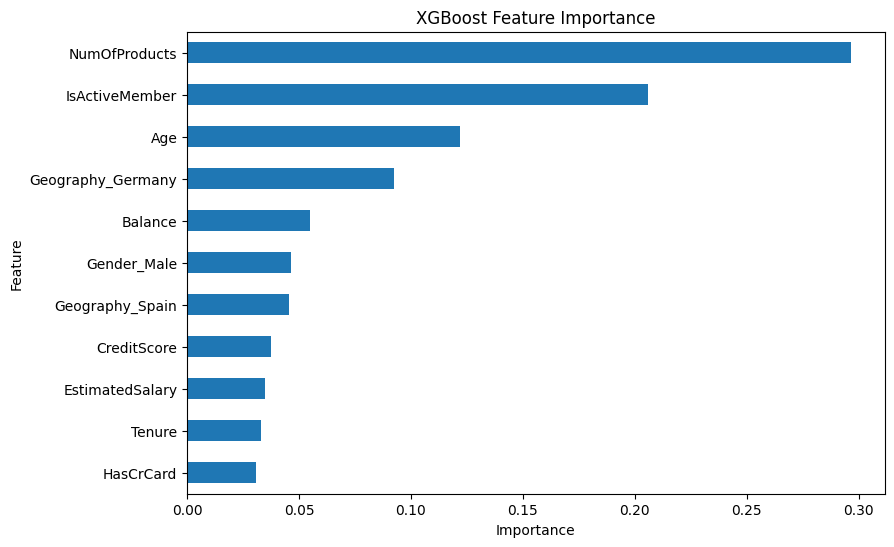

In [79]:
# XGBoost feature importance

xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))

xgb_importance.sort_values().plot(kind='barh')

plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

In [80]:
# Compare feature importance across models

importance_comparison = pd.DataFrame({
    'Random Forest': rf_importance,
    'XGBoost': xgb_importance
}).fillna(0)

importance_comparison.sort_values(
    'Random Forest',
    ascending=False
).round(4)

,Random Forest,XGBoost
Age,0.2365,0.1219
EstimatedSalary,0.1470,0.0349
CreditScore,0.1428,0.0375
Balance,0.1418,0.0547
NumOfProducts,0.1304,0.2967
Tenure,0.0818,0.0332
IsActiveMember,0.0399,0.2057
Geography_Germany,0.0289,0.0925
HasCrCard,0.0188,0.0308
Gender_Male,0.0185,0.0466


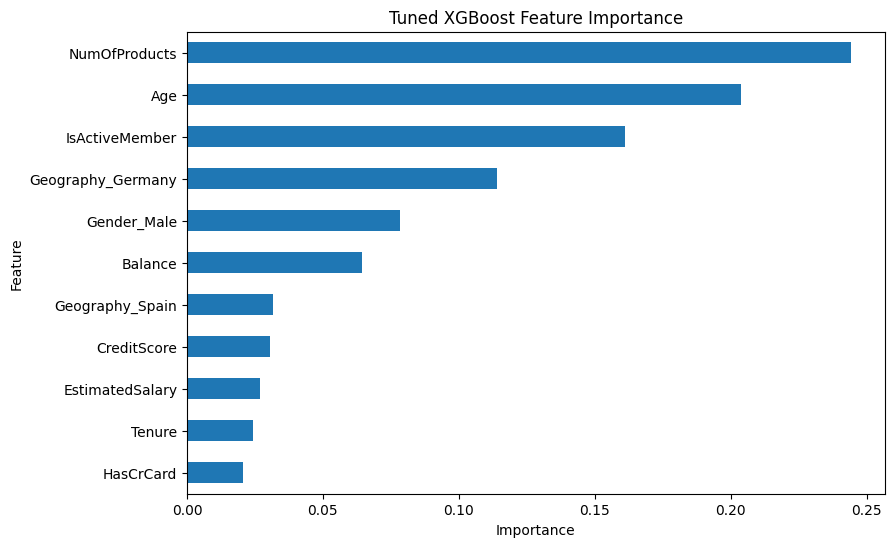

In [81]:
# Tuned XGBoost feature importance

xgb_tuned_importance = pd.Series(
    best_xgb.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))

xgb_tuned_importance.sort_values().plot(kind='barh')

plt.title('Tuned XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

Tuned XGBoost identifies number of products, age and active-member status as its most important features, followed by German geography. These variables contribute most to the model's predictions, although feature importance alone does not establish causation.

In [82]:
# SHAP analysis for tuned XGBoost

import shap

# Use a sample of the test set for interpretation
X_shap = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Explain model predictions
xgb_explainer = shap.TreeExplainer(best_xgb)

shap_values = xgb_explainer(X_shap)

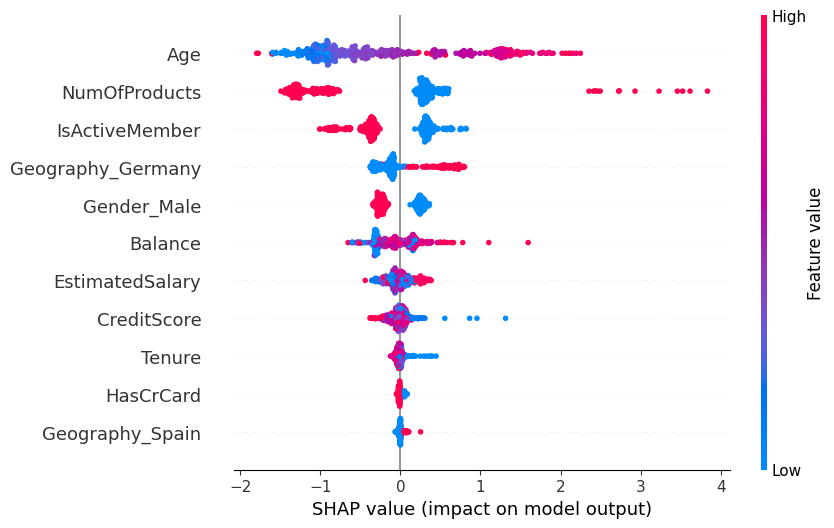

In [83]:
# SHAP feature impact summary

shap.plots.beeswarm(shap_values, max_display=11)

In [84]:
# SHAP interaction analysis

X_interaction = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)

interaction_explainer = shap.TreeExplainer(best_xgb)

interaction_values = interaction_explainer.shap_interaction_values(
    X_interaction
)

# Handle binary-classification outputs if returned as a list
if isinstance(interaction_values, list):
    interaction_values = interaction_values[-1]

print("Interaction array shape:", interaction_values.shape)

Interaction array shape: (200, 11, 11)


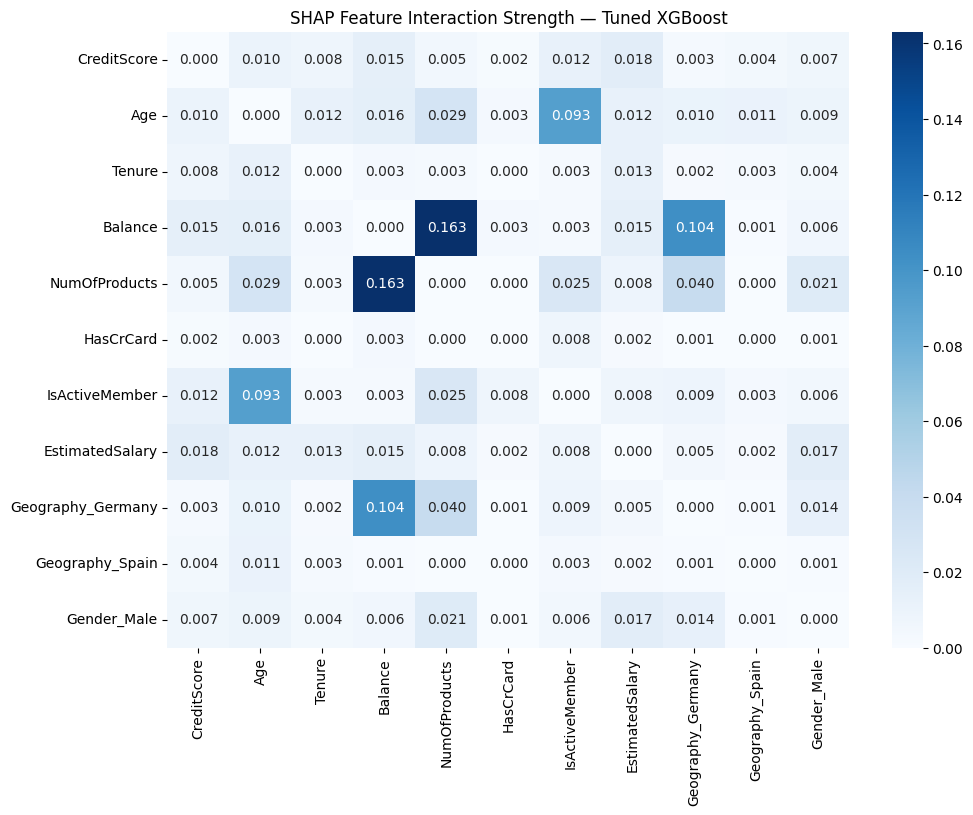

In [85]:
# Average absolute interaction strength between features

interaction_strength = np.abs(interaction_values).mean(axis=0)

interaction_df = pd.DataFrame(
    interaction_strength,
    index=X_interaction.columns,
    columns=X_interaction.columns
)

# Exclude self-interactions and retain each feature pair once
np.fill_diagonal(interaction_strength, 0)

interaction_df = pd.DataFrame(
    interaction_strength,
    index=X_interaction.columns,
    columns=X_interaction.columns
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    interaction_df,
    cmap='Blues',
    annot=True,
    fmt='.3f'
)

plt.title('SHAP Feature Interaction Strength — Tuned XGBoost')
plt.show()

In [86]:
# Identify the five strongest feature interactions

upper_triangle = np.triu(
    np.ones(interaction_df.shape, dtype=bool),
    k=1
)

top_interactions = (
    interaction_df.where(upper_triangle)
    .stack()
    .sort_values(ascending=False)
    .head(5)
)

top_interactions

Balance        NumOfProducts        0.163170
               Geography_Germany    0.103827
Age            IsActiveMember       0.092578
NumOfProducts  Geography_Germany    0.039569
Age            NumOfProducts        0.029231
dtype: float32

Feature 1: Balance
Feature 2: NumOfProducts


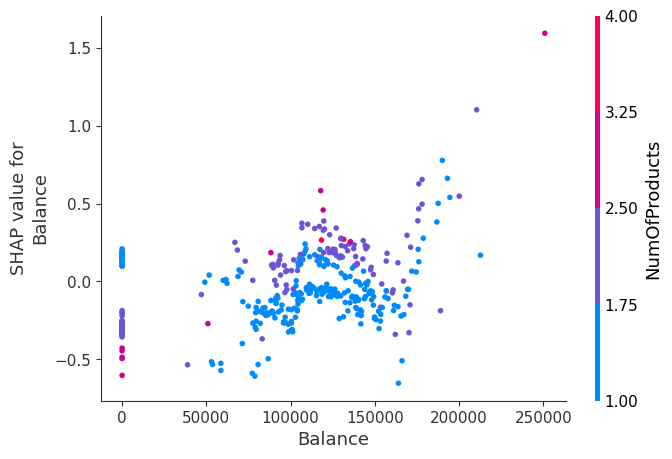

In [87]:
# Plot the strongest feature interaction

feature_1, feature_2 = top_interactions.index[0]

print("Feature 1:", feature_1)
print("Feature 2:", feature_2)

shap.dependence_plot(
    feature_1,
    shap_values.values,
    X_shap,
    interaction_index=feature_2
)

## SHAP Analysis and Business Implications

SHAP analysis identifies age, number of products and active-member status as prominent contributors to churn predictions from the tuned XGBoost model. Interaction analysis highlights balance and number of products as the strongest feature combination, followed by balance and German geography, and age and active-member status. These patterns provide hypotheses for targeted retention strategies but do not establish causation or demonstrate that interventions will prevent churn.